# Load SIR LUT

Read in the liquid water Lorenz-Mie look-up table and interpolate over an array of effective radius.

Uses scale invariance, with base values valid at 355 nm. So we need to scale to 1064 nm (CPL depol channel).

**Publication:**
Chemyakin Eduard, Stamnes Snorre, Burton Sharon P., Liu Xu, Hostetler Chris, Ferrare Richard, Cairns Brian, and Dubovik Oleg (2021)
Improved Lorenz-Mie Look-Up Table for Lidar and Polarimeter Retrievals.
Frontiers Remote Sensing. 2:711106. doi: 10.3389/frsen.2021.711106

**Data/Software URL:** https://science-data.larc.nasa.gov/polarimetry/

In [1]:
import os
import numpy as np
import xarray as xr
import h5py
from scipy.interpolate import RegularGridInterpolator
from datetime import datetime
import matplotlib.pyplot as plt

In [7]:
def load_liquid_lut(mat_filename):
    print(f"Loading Liquid LUT: {mat_filename.split('/')[-1]}...")
    with h5py.File(mat_filename, 'r') as f:
        # Access the top group
        cloud_grp = f['CloudLUT']
        
        # 1. Read Dimensions
        # Note: Matlab HDF5 is column-major. We often need to transpose (.T) 
        # to get [Real, Imag, Radius] in Python (Row-major).
        real_cri = np.squeeze(cloud_grp['RealPartsCRI'][:])
        imag_cri = np.squeeze(cloud_grp['ImagPartsCRI'][:])
        radii = np.squeeze(cloud_grp['RadiiGridBins'][:])
        angles = np.squeeze(cloud_grp['ScatteringAngles'][:])
        
        # 2. Access DataRecord Group
        data_rec = cloud_grp['DataRecord']
        
        # 3. Read Specific Optical Variables
        # Cbsc = Backscattering Cross Section (Already includes P11(180) logic!)
        # Shape usually: [Radius, Imag, Real] in Matlab -> [Real, Imag, Radius] in Python
        # CHECK SHAPES: print(C_bsc.shape) to be sure.
        C_bsc = data_rec['Cbsc'][:]
        C_ext = data_rec['Cext'][:]
        print(f"C_bsc Shape: {C_bsc.shape}")
        print(f"C_ext Shape: {C_ext.shape}")
        print(
            f"Grid Sizes: Real={len(real_cri)}, Imag={len(imag_cri)}, Rad={len(radii)}, Ang={len(angles)}"
        )
        
        # If the shape is [dim1, dim2, dim3], and radii has length dim3,
        # then no transpose needed. If radii corresponds to dim1, transpose.
        # Standard guess: Transpose is usually needed for Matlab -> Numpy.
        C_bsc = C_bsc.T
        C_ext = C_ext.T
        
    return real_cri, imag_cri, radii, C_bsc, C_ext

In [8]:
# ======================================================
# INSTRUCTIONS TO RUN FIRST
# ======================================================
# Run the load function and print the keys/shapes.
# We need to find where Q_ext (Extinction Efficiency) is hiding.
# It might be packed into DataRecord (e.g., Angle index 0 or -1).

fname_sir = (
    '/home/jfinlon/data/IMPACTS/Particle_Properties_DB/'
    'CloudLUT_100_100_0.350_700bins_1400CRI_ln2rKr_Twomey.mat'
)
lut_data = load_liquid_lut(fname_sir)

Loading Liquid LUT: CloudLUT_100_100_0.350_700bins_1400CRI_ln2rKr_Twomey.mat...
C_bsc Shape: (1400, 1)
C_ext Shape: (1400, 1)
Grid Sizes: Real=56, Imag=25, Rad=700, Ang=203


In [48]:
f = h5py.File(fname_sir, 'r')
cloud_grp = f['CloudLUT']
data_rec = cloud_grp['DataRecord']
real_cri = np.squeeze(cloud_grp['RealPartsCRI'][:])
imag_cri = np.squeeze(cloud_grp['ImagPartsCRI'][:])
radii = np.squeeze(cloud_grp['RadiiGridBins'][:]) 
angles = np.squeeze(cloud_grp['ScatteringAngles'][:])

In [46]:
cloud_grp.keys()

<KeysViewHDF5 ['DataRecord', 'ImagPartsCRI', 'NumberImagParts', 'NumberRadiiGridBins', 'NumberRealParts', 'NumberScatteringAngles', 'RadiiGridBins', 'RealPartsCRI', 'ScatteringAngles', 'WavelengthLUT']>

In [47]:
cloud_grp['NumberImagParts'][:]

array([[25]], dtype=int32)

In [49]:
data_rec.keys()

<KeysViewHDF5 ['C11', 'C12', 'C33', 'C34', 'Cbsc', 'Cext', 'Csca', 'ImagPart', 'RealPart']>

In [60]:
f[data_rec['C11'][0, 0]][:].shape

(700, 203)

In [42]:
f[cloud_grp['DataRecord']['C11'][0]]

TypeError: Accessing a group is done with bytes or str, not <class 'numpy.ndarray'>

In [35]:
c_ext_refs = data_rec['Cext']

# Initialize an empty array: (Real, Imag, Radius)
# We assume 56 and 25 based on your previous info
C_ext_3D = np.zeros((56, 25, 700)) 

# Loop through the flattened 1400 references
# We assume the 'flattening' follows the standard row-major order (56 blocks of 25)
for i in range(1400):
    # Calculate 2D indices from the flat index 'i'
    i_real = i // 25  # Integer division
    i_imag = i % 25   # Modulo
    
    # Get the reference
    ref = c_ext_refs[i, 0]
    
    # Dereference and store
    # We use [:] to ensure we get the values as a numpy array
    C_ext_3D[i_real, i_imag, :] = f[ref][:].flatten() # flatten() is just safety if it comes out (700,1)

print("Final 3D Cube Shape:", C_ext_3D.shape)

Final 3D Cube Shape: (56, 25, 700)


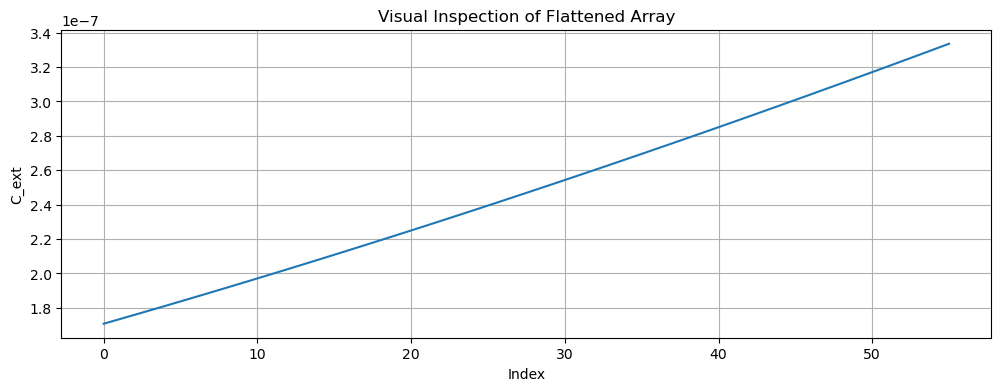

In [36]:
data_rec = cloud_grp['DataRecord']
C_bsc = data_rec['Cbsc'][:]
C_ext = data_rec['Cext'][:]

plt.figure(figsize=(12, 4))
plt.plot(C_ext_3D[:, 0, 10])
plt.title("Visual Inspection of Flattened Array")
plt.xlabel("Index")
plt.ylabel("C_ext")
plt.grid(True)
plt.show()

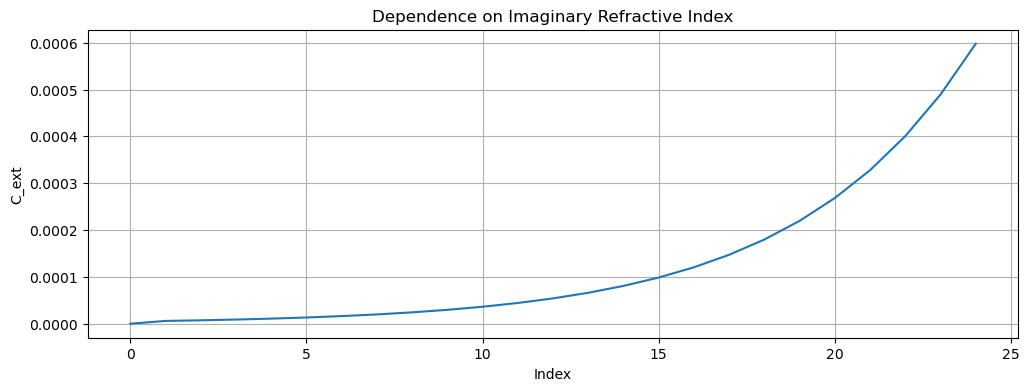

In [38]:
plt.figure(figsize=(12, 4))
plt.plot(C_ext_3D[0, :, 10]) 
plt.title("Dependence on Imaginary Refractive Index")
plt.xlabel("Index")
plt.ylabel("C_ext")
plt.grid(True)
plt.show()

---

In [2]:
def reconstruct_array(h5_file, dataset_name, expected_shape_2d):
    """
    Reconstructs dense numpy array from HDF5 object references.
    """
    print(f"Processing {dataset_name}...")
    
    # Get the array of references (1400, 1)
    ref_array = h5_file['CloudLUT']['DataRecord'][dataset_name] 
    
    # Check inner shape from the first reference
    first_ref = ref_array[0, 0]
    inner_data = h5_file[first_ref][:]
    
    # Handle (700, 1) vs (700,)
    inner_shape = inner_data.shape
    if len(inner_shape) == 2 and inner_shape[1] == 1:
        inner_shape = (inner_shape[0],)
        
    final_shape = expected_shape_2d + inner_shape
    
    # Pre-allocate output array
    out_arr = np.zeros(final_shape, dtype=np.float32)
    
    # Loop and fill
    total_refs = expected_shape_2d[0] * expected_shape_2d[1]
    
    for i in range(total_refs):
        # Map 1D index to 2D (Real, Imag) - Row Major
        r_idx = i // expected_shape_2d[1]
        i_idx = i % expected_shape_2d[1]
        
        ref = ref_array[i, 0]
        data = h5_file[ref][:]
        
        if data.shape != inner_shape:
            data = data.reshape(inner_shape)
            
        out_arr[r_idx, i_idx, ...] = data
        
    return out_arr

In [75]:
# # --- CONFIGURATION ---
# input_h5_path = (
#     '/home/jfinlon/data/IMPACTS/Particle_Properties_DB/'
#     'CloudLUT_100_100_0.350_700bins_1400CRI_ln2rKr_Twomey.mat'
# )

# # Dimensions
# n_real = 56
# n_imag = 25
# n_rad = 700
# n_ang = 203

# # Variables to process
# vars_3d = ['Cext', 'Cbsc', 'Csca']       # Shape: (Real, Imag, Radius)
# vars_4d = ['C11', 'C12', 'C33', 'C34']      # Shape: (Real, Imag, Radius, Angle)

# # --- MAIN EXECUTION ---
# with h5py.File(input_h5_path, 'r') as f_in:
#     # 1. EXTRACT COORDINATES
#     # Retrieve coordinate arrays (or placeholders if missing)
#     real_vals = np.squeeze(f_in['CloudLUT']['RealPartsCRI'][:])
#     imag_vals = np.squeeze(f_in['CloudLUT']['ImagPartsCRI'][:])
    
#     if 'RadiiGridBins' in f_in['CloudLUT']:
#         rad_vals = np.squeeze(f_in['CloudLUT']['RadiiGridBins'][:])
#     else:
#         print("Warning: 'Radii' not found, using placeholder.")
#         rad_vals = np.logspace(np.log10(1e-3), np.log10(500), n_rad)

#     if 'ScatteringAngles' in f_in['CloudLUT']:
#         ang_vals = np.squeeze(f_in['CloudLUT']['ScatteringAngles'][:])
#     else:
#         print("Warning: 'ScatteringAngles' not found, using placeholder.")
#         ang_vals = np.linspace(0, 180, n_ang)

#     # 2. BUILD DATA DICTIONARY
#     data_vars = {}
    
#     # Process 3D Variables
#     for var_name in vars_3d:
#         data_numpy = reconstruct_array(f_in, var_name, (n_real, n_imag))
        
#         # Create DataArray
#         da = xr.DataArray(
#             data_numpy,
#             dims=['real', 'imag', 'radius'],
#             coords={'real': real_vals, 'imag': imag_vals, 'radius': rad_vals},
#             attrs={'units': 'microns^2', 'long_name': f'{var_name} Cross Section'}
#         )
#         data_vars[var_name] = da

#     # Process 4D Variables
#     for var_name in vars_4d:
#         data_numpy = reconstruct_array(f_in, var_name, (n_real, n_imag))
        
#         # Determine dims based on result
#         if data_numpy.ndim == 4:
#             dims = ['real', 'imag', 'radius', 'angle']
#             coords = {'real': real_vals, 'imag': imag_vals, 'radius': rad_vals, 'angle': ang_vals}
#         else:
#             # Fallback if variable turned out to be 3D
#             dims = ['real', 'imag', 'radius']
#             coords = {'real': real_vals, 'imag': imag_vals, 'radius': rad_vals}
            
#         # Create DataArray
#         da = xr.DataArray(
#             data_numpy,
#             dims=dims,
#             coords=coords,
#             attrs={'units': 'sr^-1' if var_name=='C11' else 'unitless', 
#                    'long_name': f'Scattering Matrix Element {var_name}'}
#         )
#         data_vars[var_name] = da

#     # 3. CREATE DATASET
#     ds = xr.Dataset(data_vars)
    
#     # Add Global Attributes
#     ds.attrs = {
#         'description': 'Reconstructed Liquid Cloud LUT',
#         'history': f'Created {datetime.now().isoformat()}',
#         'source_file': input_h5_path
#     }

Processing Cext...
Processing Cbsc...
Processing Csca...
Processing C11...
Processing C12...
Processing C33...
Processing C34...


In [3]:
# --- CONFIGURATION ---
input_h5_path = (
    '/home/jfinlon/data/IMPACTS/Particle_Properties_DB/'
    'CloudLUT_100_100_0.350_700bins_1400CRI_ln2rKr_Twomey.mat'
)

# Dimensions
n_real = 56
n_imag = 25
n_rad = 700
n_ang = 203

# Variables to process
vars_3d = ['Cext', 'Cbsc', 'Csca']       # Shape: (Real, Imag, Radius)
vars_4d = ['C11', 'C12', 'C33', 'C34']   # Shape: (Real, Imag, Radius, Angle)

# --- MAIN EXECUTION ---
with h5py.File(input_h5_path, 'r') as f_in:
    # 1. EXTRACT COORDINATES
    real_vals = np.squeeze(f_in['CloudLUT']['RealPartsCRI'][:])
    imag_vals = np.squeeze(f_in['CloudLUT']['ImagPartsCRI'][:])
    
    if 'RadiiGridBins' in f_in['CloudLUT']:
        rad_vals = np.squeeze(f_in['CloudLUT']['RadiiGridBins'][:])
    else:
        print("Warning: 'Radii' not found, using placeholder.")
        rad_vals = np.logspace(np.log10(1e-3), np.log10(500), n_rad)

    if 'ScatteringAngles' in f_in['CloudLUT']:
        ang_vals = np.squeeze(f_in['CloudLUT']['ScatteringAngles'][:])
    else:
        print("Warning: 'ScatteringAngles' not found, using placeholder.")
        ang_vals = np.linspace(0, 180, n_ang)

    # 2. BUILD DATA DICTIONARY
    data_vars = {}
    
    # Process 3D Variables
    for var_name in vars_3d:
        data_numpy = reconstruct_array(f_in, var_name, (n_real, n_imag))
        
        da = xr.DataArray(
            data_numpy,
            dims=['real', 'imag', 'radius'],
            coords={'real': real_vals, 'imag': imag_vals, 'radius': rad_vals},
            # FIX: Correct units to volume-normalized dimensions (um^-1)
            attrs={'units': 'um^-1', 'long_name': f'{var_name} Volume-Normalized Coefficient'}
        )
        data_vars[var_name] = da

    # Process 4D Variables
    for var_name in vars_4d:
        data_numpy = reconstruct_array(f_in, var_name, (n_real, n_imag))
        
        if data_numpy.ndim == 4:
            dims = ['real', 'imag', 'radius', 'angle']
            coords = {'real': real_vals, 'imag': imag_vals, 'radius': rad_vals, 'angle': ang_vals}
        else:
            dims = ['real', 'imag', 'radius']
            coords = {'real': real_vals, 'imag': imag_vals, 'radius': rad_vals}
            
        da = xr.DataArray(
            data_numpy,
            dims=dims,
            coords=coords,
            attrs={'units': 'um^-1 sr^-1', 'long_name': f'Scattering Matrix Element {var_name}'}
        )
        data_vars[var_name] = da

    # 3. CREATE DATASET
    ds = xr.Dataset(data_vars)
    
    # Add Global Attributes
    ds.attrs = {
        'description': 'Reconstructed Liquid Cloud LUT',
        'history': f'Created {datetime.now().isoformat()}',
        'source_file': input_h5_path,
        'wavelength_lut_um': 0.355
    }

Processing Cext...
Processing Cbsc...
Processing Csca...
Processing C11...
Processing C12...
Processing C33...
Processing C34...


In [4]:
ds

<xarray.Dataset> Size: 3GB
Dimensions:  (real: 56, imag: 25, radius: 700, angle: 203)
Coordinates:
  * real     (real) float64 448B 1.25 1.252 1.254 1.256 ... 1.356 1.358 1.36
  * imag     (imag) float64 200B 0.0 1e-05 1.222e-05 ... 0.00067 0.0008185 0.001
  * radius   (radius) float64 6kB 0.001 0.001019 0.001038 ... 481.6 490.7 500.0
  * angle    (angle) float64 2kB 0.0 0.2 0.4 0.6 0.8 ... 179.4 179.6 179.8 180.0
Data variables:
    Cext     (real, imag, radius) float32 4MB 9.723e-08 1.029e-07 ... 5.645e-05
    Cbsc     (real, imag, radius) float32 4MB 1.16e-08 1.228e-08 ... 5.224e-08
    Csca     (real, imag, radius) float32 4MB 9.723e-08 1.029e-07 ... 3.025e-05
    C11      (real, imag, radius, angle) float32 796MB 1.459e-07 ... 6.565e-07
    C12      (real, imag, radius, angle) float32 796MB 0.0 -8.887e-13 ... 0.0
    C33      (real, imag, radius, angle) float32 796MB 1.459e-07 ... -6.552e-07
    C34      (real, imag, radius, angle) float32 796MB 0.0 -7.614e-24 ... 0.0
Attributes:
    description:        Reconstructed Liquid Cloud LUT
    history:            Created 2026-05-19T13:31:07.279086
    source_file:        /home/jfinlon/data/IMPACTS/Particle_Properties_DB/Clo...
    wavelength_lut_um:  0.355

In [5]:
# Save Dataset to file
output_nc_path = os.path.join(os.path.dirname(input_h5_path), 'SIR_Liquid_LUT.nc')

# Define compression (zlib=True) for all variables
encoding = {var: {'zlib': True, 'complevel': 4} for var in ds.data_vars}

print(f"Saving to {output_nc_path}...")
ds.to_netcdf(output_nc_path, encoding=encoding)
print("Done!")

Saving to /home/jfinlon/data/IMPACTS/Particle_Properties_DB/SIR_Liquid_LUT.nc...
Done!


---

In [83]:
import matplotlib.pyplot as plt

def get_liquid_properties(ds, target_real_n, target_imag_k):
    """
    Extracts liquid optical properties from the LUT for a specific Refractive Index.
    
    Args:
        ds (xr.Dataset): The SIR Liquid LUT (loaded via xarray).
        target_real_n (float): The Real part of refractive index (e.g., 1.34).
        target_imag_k (float): The Imaginary part (e.g., 1.0e-9).
        
    Returns:
        dict: containing vectors for 'radius', 'beta_par', 'beta_perp', 'extinction_cs'
    """
    
    # 1. Select nearest Refractive Index from the LUT
    # method='nearest' finds the closest grid point in the 56x25 grid
    # We select C_bsc (Backscatter Cross Section) and C_ext (Extinction Cross Section)
    subset = ds.sel(real=target_real_n, imag=target_imag_k, method='nearest')
    
    # Extract the vectors (they will depend on 'radius')
    radii = subset['radius'].values
    C_bsc = subset['C_bsc'].values  # Units: microns^2
    C_ext = subset['C_ext'].values  # Units: microns^2
    
    # 2. Calculate Beta Parallel and Perpendicular
    # Physics Assumption: Liquid droplets are spherical -> Depolarization = 0.
    # Therefore:
    #   beta_perp = 0
    #   beta_par  = C_bsc  (all backscatter is parallel)
    
    beta_par = C_bsc
    beta_perp = np.zeros_like(C_bsc) # Strictly zero for single scattering
    
    return {
        'radius': radii,
        'beta_par': beta_par,
        'beta_perp': beta_perp,
        'C_ext': C_ext
    }

In [2]:
def get_ref_index(temperature):
    '''Get the real and imaginary components of the water refractive index based on temperature.
    Look up tables from this site: https://refractiveindex.info/?shelf=main&book=H2O&page=Hale
    Uses Hale & Querry (https://doi.org/10.1364/AO.12.000555) for warm liquid (> 0C).
    Uses Rowe et al. (https://doi.org/10.1029/2020JD032624) for SCLW at different temperatures.
    '''
    if temperature >= 0.:
        ref_index_real, ref_index_imag = (1.327, 2.89e-6)
    elif (temperature < 0.) and (temperature >= -5.):
        ref_index_real, ref_index_imag = (1.3229585, 1.2181699e-6)
    elif (temperature < -5.) and (temperature >= -15.):
        ref_index_real, ref_index_imag = (1.3235222, 1.2181699e-6)
    elif (temperature < -15.) and (temperature >= -26.5):
        ref_index_real, ref_index_imag = (1.3237735, 1.2181699e-6)
    else:
        ref_index_real, ref_index_imag = (1.3241966, 1.2181699e-6)
    
    return ref_index_real, ref_index_imag

def integrate_liquid_psd(ds, target_reffs, ref_real, ref_imag, mu=0):
    """
    Calculates Bulk Optical Properties by integrating single-scattering LUT 
    over a Gamma PSD for a range of target effective radii.

    Args:
        ds (xr.Dataset): The Liquid LUT.
        target_reffs (array): List of target effective radii (microns) to calculate for.
        ref_real, ref_imag (float): Refractive index to select from LUT.
        mu (int): Gamma distribution shape parameter (0 = Exponential, 2 = Standard Cloud).
                  Chemyakin often assumes mu=0 or mu=2.

    Returns:
        dict: 'reff', 'sigma_bsc_avg', 'sigma_ext_avg', 'S_ratio'
              (Sigma values are Mean Cross Sections per particle in microns^2)
    """
    
    # 1. Select the specific Refractive Index (Single Particle Properties)
    # We slice the LUT once to get the C_bsc(r) and C_ext(r) curves
    lut_slice = ds.sel(real=ref_real, imag=ref_imag, method='nearest')
    
    r_lut = lut_slice['radius'].values      # The geometric radii grid (0.001 to 500)
    C_bsc_lut = lut_slice['Cbsc'].values   # Backscatter CS vs Radius
    C_ext_lut = lut_slice['Cext'].values   # Extinction CS vs Radius
    
    # Pre-allocate output arrays
    avg_C_bsc = np.zeros_like(target_reffs)
    avg_C_ext = np.zeros_like(target_reffs)
    
    for i, reff_target in enumerate(target_reffs):
        if reff_target <= 0: continue
        
        # Gamma PSD Setup
        lam = (mu + 3) / reff_target
        n_r = (r_lut ** mu) * np.exp(-lam * r_lut)
        n_r[n_r < 1e-30] = 0 # Numerical cleanup
        
        norm_factor = trapezoid(n_r, r_lut)
        
        if norm_factor > 0:
            avg_C_bsc[i] = trapezoid(n_r * C_bsc_lut, r_lut) / norm_factor
            avg_C_ext[i] = trapezoid(n_r * C_ext_lut, r_lut) / norm_factor
        else:
            avg_C_bsc[i] = np.nan
            avg_C_ext[i] = np.nan

    # 3. Calculate Components (Spherical Assumption)
    # Total Backscatter = Parallel + Perpendicular
    # For spheres: Perpendicular = 0, so Parallel = Total
    
    sigma_par_avg = avg_C_bsc.copy()      # All backscatter is parallel
    sigma_perp_avg = np.zeros_like(avg_C_bsc) # No depolarization
    
    # Calculate Lidar Ratio
    S_ratio = np.divide(avg_C_ext, avg_C_bsc, out=np.zeros_like(avg_C_bsc), where=avg_C_bsc!=0)
    
    return {
        'reff': target_reffs,
        'sigma_bsc_avg': avg_C_bsc,    # Total Backscatter (per particle)
        'sigma_par_avg': sigma_par_avg, # Parallel Component
        'sigma_perp_avg': sigma_perp_avg, # Perpendicular Component
        'sigma_ext_avg': avg_C_ext,
        'S_ratio': S_ratio
    }

In [3]:
fname_lut = '/home/jfinlon/data/IMPACTS/Particle_Properties_DB/SIR_Liquid_LUT.nc'
ds = xr.open_dataset(fname_lut)
ds

<xarray.Dataset> Size: 3GB
Dimensions:  (real: 56, imag: 25, radius: 700, angle: 203)
Coordinates:
  * real     (real) float64 448B 1.25 1.252 1.254 1.256 ... 1.356 1.358 1.36
  * imag     (imag) float64 200B 0.0 1e-05 1.222e-05 ... 0.00067 0.0008185 0.001
  * radius   (radius) float64 6kB 0.001 0.001019 0.001038 ... 481.6 490.7 500.0
  * angle    (angle) float64 2kB 0.0 0.2 0.4 0.6 0.8 ... 179.4 179.6 179.8 180.0
Data variables:
    Cext     (real, imag, radius) float32 4MB ...
    Cbsc     (real, imag, radius) float32 4MB ...
    Csca     (real, imag, radius) float32 4MB ...
    C11      (real, imag, radius, angle) float32 796MB ...
    C12      (real, imag, radius, angle) float32 796MB ...
    C33      (real, imag, radius, angle) float32 796MB ...
    C34      (real, imag, radius, angle) float32 796MB ...
Attributes:
    description:  Reconstructed Liquid Cloud LUT
    history:      Created 2025-12-18T12:59:41.309313
    source_file:  /home/jfinlon/data/IMPACTS/Particle_Properties_DB/CloudLUT_...

In [5]:
from scipy.integrate import trapezoid

# --- CONFIGURATION ---
temperature = -10
ref_index_real, ref_index_imag = get_ref_index(temperature)

# 1. Load Data
# input_h5_path = '/home/jfinlon/data/IMPACTS/Particle_Properties_DB/SIR_Liquid_LUT.nc'
# ds = xr.open_dataset(input_h5_path)

# 2. Get Properties
target_reffs = np.linspace(10, 2000, 200)
all_props = []
for temp in [-40, -30, -20, -10]:
    ref_index_real, ref_index_imag = get_ref_index(temp)
    print(f"T = {temp}C | Real = {ref_index_real:0.3f} | Imag = {ref_index_imag:.3e}")
    props = integrate_liquid_psd(ds, target_reffs, ref_index_real, ref_index_imag)
    all_props.append(props)
# props = integrate_liquid_psd(ds, target_reffs, ref_index_real, ref_index_imag)

T = -40C | Real = 1.324 | Imag = 1.218e-06
T = -30C | Real = 1.324 | Imag = 1.218e-06
T = -20C | Real = 1.324 | Imag = 1.218e-06
T = -10C | Real = 1.324 | Imag = 1.218e-06


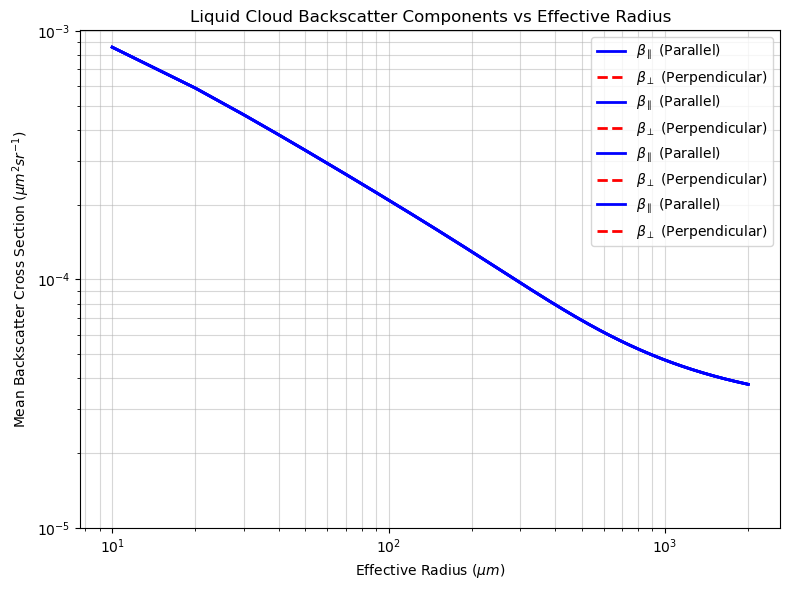

In [23]:
fig, ax = plt.subplots(figsize=(8, 6))

# Plot Parallel (Blue Solid)
for props in all_props:
    ax.plot(props['reff'], props['sigma_par_avg'], label=r'$\beta_{\parallel}$ (Parallel)', color='blue', linewidth=2)
    
    # Plot Perpendicular (Red Dashed) - This will be a flat line at 0
    ax.plot(props['reff'], props['sigma_perp_avg'], label=r'$\beta_{\perp}$ (Perpendicular)', color='red', linestyle='--', linewidth=2)

ax.set_title("Liquid Cloud Backscatter Components vs Effective Radius")
ax.set_xlabel(r"Effective Radius ($\mu m$)")
ax.set_ylabel(r"Mean Backscatter Cross Section ($\mu m^2 sr^{-1}$)")

# Log-Log helps visualize the power law growth of Parallel backscatter
ax.set_xscale('log')
ax.set_yscale('log') 

# LIMIT FIX: Since beta_perp is 0, it won't show on log scale. 
# You might want to set a small y-min to see the blue curve clearly.
ax.set_ylim(bottom=1e-5) 

ax.legend()
ax.grid(True, which="both", ls="-", alpha=0.5)

plt.tight_layout()
plt.show()